# 04 — Cepstral feature comparison

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495), Sections **3.4 and 4.2**

## 1. Objective

Notebook 03 trained one mixture per species on the 20 modified-filterbank cepstral coefficients
(m-FCC) of notebook 02. This notebook asks the article's next question: does the modified filter
bank actually beat the standard representations?

`[PAPER]` Section 4.2 trains the same GMMs on four feature sets and plots the weighted error rate
(WER) against the number of Gaussians, with **12 seconds** of calls per species (its Figure 9):

- **12 MFCC** and **20 MFCC**, the standard mel-frequency cepstra;
- **20 PLP-RASTA**;
- **20 m-FCC**, the article's modified filter bank.

`[PAPER]` The article reports that standard MFCC performs worst, improving slightly from 12 to 20
coefficients, that PLP-RASTA improves on MFCC by about 1 % when more than 16 mixtures are used, and
that m-FCC surpasses the others.

The notebook also completes what notebook 03 left out: **Figure 8**, which the article draws with
**12 MFCC** and the three training durations.

### Scope

Only the labelled calls of the Mendeley collection (`MENDELEY_CALL_DIR`) are used. No pond recordings,
no thresholds and no presence-absence labels are involved.

### What the article does not specify

The article gives no implementation parameters for either baseline. The MFCC and PLP-RASTA features
are therefore **reconstructions**, built in `frog_presence.features` with every parameter named, and
the m-FCC are those stored by notebook 02. Whatever this notebook finds about the baselines is a
finding about *these* reconstructions.

## 2. Setup

**What this section asks, and why it matters.** The audio lives outside the repository, so the
collection is located through `.env`. Nothing is inspected here except that the folder exists.

In [1]:
# Every dependency, the display options, the dataset location from .env and the artefacts of notebook 02.
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from joblib import Parallel, delayed

from frog_presence import features as F
from frog_presence.audio import index_wavs, read_call_audio as read_samples
from frog_presence.gmm import (
    CallCorpus, build_recording_split, build_split, evaluate_models, fit_species_models,
)

sns.set_theme(style="ticks")
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 140)
pd.set_option("display.max_columns", 80)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
RESULTS_DIR = PROCESSED_DIR / "feature_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_PATH = PROCESSED_DIR / "features.npy"
LABELS_PATH = PROCESSED_DIR / "labels.npy"
CALLS_PATH = PROCESSED_DIR / "calls.csv"

for path in (FEATURES_PATH, LABELS_PATH, CALLS_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.name}. Run notebooks/02_preprocessing.ipynb first.")

load_dotenv(REPO_ROOT / ".env")


def dataset_dir(variable: str) -> Path:
    """Read one dataset location from the environment, failing with a message that explains itself."""
    value = os.environ.get(variable)
    if not value:
        raise RuntimeError(f"{variable} is not set. Copy .env.example to .env and fill in the paths.")
    return Path(value).expanduser()


MENDELEY_CALL_DIR = dataset_dir("MENDELEY_CALL_DIR")
if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(f"The folder configured as MENDELEY_CALL_DIR ({MENDELEY_CALL_DIR.name}) does not exist.")

# Only folder names are printed: the full paths are personal to whoever runs the notebook.
print("Dataset used   : MENDELEY_CALL_DIR ->", MENDELEY_CALL_DIR.name)
print("Results written:", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
print("CPU workers    :", os.cpu_count())

Dataset used   : MENDELEY_CALL_DIR -> mendeley
Results written: data/processed/feature_comparison
CPU workers    : 32


## 3. Load the stored m-FCC and the call boundaries

**What this section asks, and why it matters.** The three baselines have to be computed from the
*same audio* as the stored m-FCC, or the comparison would partly measure different audio. That needs
the sample boundaries of every call. Notebook 02 now stores them next to the call table, and this
section checks that the stored table, the stored labels and the stored frames all describe the same
calls before anything is recomputed.

In [2]:
# Load the m-FCC matrix, the labels and the call table, and check that they describe the same frames.
mfcc_modified_all = np.load(FEATURES_PATH)
labels = np.load(LABELS_PATH)
calls_csv = pd.read_csv(CALLS_PATH)

required = {"code", "species", "wav", "rate", "seconds", "frames", "start", "end"}
missing = required - set(calls_csv.columns)
if missing:
    raise ValueError(f"calls.csv is missing columns {sorted(missing)}; re-run notebook 02.")

assert mfcc_modified_all.shape[1] == 20 and len(mfcc_modified_all) == len(labels)
assert int(calls_csv["frames"].sum()) == len(mfcc_modified_all)

corpus_mfcc = CallCorpus(mfcc_modified_all, calls_csv)
calls = corpus_mfcc.calls

for row in calls.itertuples(index=False):
    if not np.all(labels[row.frame_start:row.frame_stop] == row.code):
        raise AssertionError(f"Stored labels do not match {row.call_id}.")

duration_gap = ((calls.end - calls.start) / calls.rate - calls.seconds).abs().max()
print("stored m-FCC       :", mfcc_modified_all.shape)
print("calls              :", len(calls))
print("labels match calls : True")
print("largest gap between (end - start) / rate and the stored duration:", f"{duration_gap:.1e} s")
display(calls[["call_id", "code", "wav", "rate", "start", "end", "seconds", "frames"]].head())

stored m-FCC       : (136005, 20)
calls              : 1461
labels match calls : True
largest gap between (end - start) / rate and the stored duration: 0.0e+00 s


,call_id,code,wav,rate,start,end,seconds,frames
0,call_0000,f01,1101.WAV,44100,20598,37356,0.38,73
1,call_0001,f01,1101.WAV,44100,173184,189942,0.38,73
2,call_0002,f01,1101.WAV,44100,449250,467772,0.42,81
3,call_0003,f01,1101.WAV,44100,815280,836448,0.48,93
4,call_0004,f01,1101.WAV,44100,1135446,1156614,0.48,93


`[OBSERVED]` The stored m-FCC matrix has **136005 rows and 20 columns**, the call table holds **1461 calls**, and
every frame of every call carries that call's label. The sample boundaries stored by notebook 02 reproduce
each stored duration exactly (largest gap 0.0 seconds), so the interval of every call is the one its m-FCC
were computed from.

## 4. Cut one call from its recording

**What this section asks, and why it matters.** The baselines are computed from the original audio,
so the cut has to return exactly the samples the m-FCC were computed from. One call is cut and
described before every call is processed.

In [3]:
# Locate every WAV the annotations refer to (refusing duplicate names), and cut one call with its stored boundaries.
WAV_ON_DISK = index_wavs(MENDELEY_CALL_DIR)
not_found = sorted(set(calls.wav.str.lower()) - set(WAV_ON_DISK))
assert not not_found, f"WAV files not found: {not_found[:5]}"


def read_call_audio(wav: str, start: int, end: int, rate: int):
    """Read the samples of one call, refusing anything that does not match its annotation."""
    return read_samples(WAV_ON_DISK[wav.lower()], start, end, rate)


first = calls.iloc[0]
example_audio, example_sr = read_call_audio(first.wav, first.start, first.end, first.rate)
print("recording      :", first.wav)
print("samples read   :", len(example_audio), "at", example_sr, "Hz")
print("duration       :", round(len(example_audio) / example_sr, 4), "s")
print("stored duration:", round(float(first.seconds), 4), "s")
print("WAV files referenced and found:", calls.wav.str.lower().nunique())

recording      : 1101.WAV
samples read   : 16758 at 44100 Hz
duration       : 0.38 s
stored duration: 0.38 s
WAV files referenced and found: 66


`[OBSERVED]` The first call is cut as **16758 samples at 44100 Hz**, which is 0.38 seconds, the stored duration.
The calls refer to **66 recordings**, and all of them were found in `MENDELEY_CALL_DIR`.

## 5. Build the four feature sets

**What this section asks, and why it matters.** Each call is turned into a matrix of frames for each
of the four representations. All of them share the front end of notebook 02 (pre-emphasis, 20 ms
frames with 75 % overlap, Hamming window, 1024-point transform), so the only thing that differs
between the sets is what is done with the spectrum.

`[PAPER]` Section 3.4 describes the m-FCC chain; for MFCC and PLP-RASTA the article names the feature
sets and gives no parameters.

*Decisions, not stated in the article, for the reconstructed baselines:*

- **MFCC:** 40 triangular mel filters from 0 Hz to the Nyquist frequency (librosa's mel scale),
  logarithm, DCT, and the first 12 or 20 coefficients, **counting c0**. The m-FCC of notebook 02
  count c0 as well, so the three are treated alike.
- **PLP-RASTA:** 24 critical bands equally spaced on the Bark scale up to the Nyquist frequency, the
  logarithm of each band filtered along time with the classic RASTA filter, equal-loudness weighting,
  cube-root compression, an all-pole model of order 20, and 20 cepstral coefficients. The RASTA filter
  starts each call from a silent state (``"zero"``); section 12 examines what that choice does.

Calls are processed in parallel, which changes the time taken and nothing else.

In [4]:
# Compute 12 MFCC, 20 MFCC and 20 PLP-RASTA for every call, and attach the stored 20 m-FCC.
FEATURE_NAMES = ("12_MFCC", "20_MFCC", "20_PLP_RASTA", "20_mFCC")


def extract_baselines(wav, start, end, rate):
    """The three reconstructed feature sets of one call."""
    audio, sr = read_call_audio(wav, start, end, rate)
    return {
        "12_MFCC": F.standard_mfcc(audio, sr, 12),
        "20_MFCC": F.standard_mfcc(audio, sr, 20),
        "20_PLP_RASTA": F.plp_rasta(audio, sr, n_cepstra=20, rasta="zero"),
    }


extracted = Parallel(n_jobs=-1)(
    delayed(extract_baselines)(r.wav, r.start, r.end, r.rate) for r in calls.itertuples(index=False))

CALL_FEATURES = {
    row.call_id: {**baselines, "20_mFCC": corpus_mfcc.features[row.frame_start:row.frame_stop]}
    for row, baselines in zip(calls.itertuples(index=False), extracted)
}
print("calls processed:", len(CALL_FEATURES))

calls processed: 1461


In [5]:
# Check every matrix is finite and has the expected width, and that the sets agree on the frame count.
EXPECTED_DIMS = {"12_MFCC": 12, "20_MFCC": 20, "20_PLP_RASTA": 20, "20_mFCC": 20}

validation_rows = []
for call_id, sets in CALL_FEATURES.items():
    for name in FEATURE_NAMES:
        X = sets[name]
        validation_rows.append({
            "call_id": call_id, "feature": name, "n_frames": len(X), "n_dimensions": X.shape[1],
            "valid": bool(X.ndim == 2 and X.shape[1] == EXPECTED_DIMS[name] and len(X) > 0 and np.isfinite(X).all()),
        })

feature_validation = pd.DataFrame(validation_rows)
if not feature_validation.valid.all():
    display(feature_validation[~feature_validation.valid].head(20))
    raise RuntimeError("invalid call-feature matrices")

frames_per_call = feature_validation.pivot(index="call_id", columns="feature", values="n_frames")
assert (frames_per_call.nunique(axis=1) == 1).all(), "the feature sets disagree on the number of frames"
assert (frames_per_call["20_mFCC"].to_numpy() == calls.set_index("call_id").frames.reindex(frames_per_call.index).to_numpy()).all()

display(feature_validation.groupby("feature").agg(
    calls=("call_id", "nunique"), total_frames=("n_frames", "sum"),
    median_frames=("n_frames", "median"), dimensions=("n_dimensions", "first")))
print("every call has the same number of frames in all four sets: True")

,calls,total_frames,median_frames,dimensions
feature,,,,
12_MFCC,1461,136005,81.0,12
20_MFCC,1461,136005,81.0,20
20_PLP_RASTA,1461,136005,81.0,20
20_mFCC,1461,136005,81.0,20


every call has the same number of frames in all four sets: True


`[OBSERVED]` All four feature sets cover the same **1461 calls and 136005 frames**, with a median of 81 frames
per call. The widths are 12, 20, 20 and 20 as expected, every value is finite, and every call has exactly the
same number of frames in all four sets.

`[INFERENCE]` The sets share the front end, so any difference found below between them is not a difference in
framing: it comes from what is done with each frame's spectrum.

## 6. One split, one seed scheme, for every feature set

**What this section asks, and why it matters.** If each representation received different training
calls, or a different random start for EM, the comparison would partly measure luck. So the
comparison is controlled: for a given repeat the **same calls** go to training and to validation for
all four feature sets, and the random start of every mixture depends on the species, the repeat and the
number of components but **not on the feature set**. Only the features change.

The splits and seeds are those of notebook 03, which has two consequences that are checked below.
The m-FCC results here must reproduce notebook 03's 12-second results exactly, and any difference
between feature sets is not an accident of initialisation.

*Decision, not stated in the article:* ten reproducible random selections, as in notebook 03.

In [6]:
# Fix the grid, derive the usable species as in notebook 03, and build one corpus per feature set.
TRAINING_DURATIONS = (6, 12, 18)
N_COMPONENTS_GRID = (2, 4, 8, 16, 32, 64)
N_REPEATS = 10
BASE_SEED = 20260814

species_seconds = calls.groupby("code").seconds.sum()
USABLE_CODES = tuple(species_seconds[species_seconds > max(TRAINING_DURATIONS)].index)
print("Usable species:", USABLE_CODES)

base_calls = calls[["code", "species", "wav", "seconds", "frames"]]


def corpus_from(matrices_by_call: dict, name: str) -> CallCorpus:
    """A corpus of one feature set, with the frames of the calls stacked in call order."""
    return CallCorpus(np.vstack([matrices_by_call[cid][name] for cid in calls.call_id]), base_calls)


CORPORA = {name: corpus_from(CALL_FEATURES, name) for name in FEATURE_NAMES}

# The split depends on the calls only, so it is the same object for every feature set.
train_ids, validation_ids, split_summary = build_split(base_calls.assign(call_id=calls.call_id), USABLE_CODES, 12, 0, BASE_SEED)
display(split_summary[["code", "training_seconds_actual", "n_train_calls", "n_validation_calls"]].round(2))
assert all(CORPORA[n].calls.call_id.equals(calls.call_id) for n in FEATURE_NAMES)
print("All four corpora index the same calls, so one split serves them all.")

Usable species: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')


,code,training_seconds_actual,n_train_calls,n_validation_calls
0,f01,12.10,26,72
1,f02,12.08,28,71
2,f03,12.60,19,150
3,f04,12.22,30,156
4,f05,12.18,35,305
5,f06,12.46,27,27
6,f07,12.54,23,78
7,f08,12.66,11,85
8,f10,12.22,29,287


All four corpora index the same calls, so one split serves them all.


`[OBSERVED]` The first repeat at 12 seconds gives the same split as the one printed in notebook 03: for `f01`
26 training calls (12.10 seconds) and 72 validation calls, for `f08` 11 training calls, and validation sets from
27 (`f06`) to 305 (`f05`) calls. The four corpora index the same calls, so one split serves all four feature
sets.

## 7. Run the Figure 9 grid

**What this section asks, and why it matters.** This is the experiment of Section 4.2: four feature
sets × six model orders × ten random selections, at 12 seconds per species. Every cell is one
condition of notebook 03's procedure, with the feature set as the only difference.

Besides the error, each fit records whether EM converged and how many iterations it needed.

In [7]:
# Fit and score one (feature set, protocol, duration, repeat) cell for every model order.
def run_cell(corpus, feature, protocol, target_seconds, repeat, orders):
    """Per-species results of one split of one feature set, for each number of components."""
    splitter = build_split if protocol == "paper" else build_recording_split
    train, validation, summary = splitter(corpus.calls, USABLE_CODES, target_seconds, repeat, BASE_SEED)
    blocks = []
    for n_components in orders:
        models = fit_species_models(corpus, train, n_components, target_seconds, repeat, BASE_SEED)
        per_species, _, _ = evaluate_models(models, corpus, validation, summary,
                                            n_components, target_seconds, repeat)
        per_species["converged"] = per_species.code.map({c: bool(m.converged_) for c, m in models.items()})
        per_species["n_iter"] = per_species.code.map({c: int(m.n_iter_) for c, m in models.items()})
        per_species["feature"], per_species["protocol"] = feature, protocol
        blocks.append(per_species)
    return pd.concat(blocks, ignore_index=True)


def run_grid(corpora, features, protocol, durations, orders=N_COMPONENTS_GRID, repeats=N_REPEATS):
    """Run every (feature set, duration, repeat) cell in parallel and stack the per-species tables."""
    jobs = [(f, d, r) for f in features for d in durations for r in range(repeats)]
    blocks = Parallel(n_jobs=-1)(
        delayed(run_cell)(corpora[f], f, protocol, d, r, orders) for f, d, r in jobs)
    return pd.concat(blocks, ignore_index=True)


def wer_by_repeat(per_species: pd.DataFrame) -> pd.DataFrame:
    """Weighted error rate (%) of each condition: the mean of the per-species errors."""
    keys = ["feature", "protocol", "training_seconds_target", "n_components", "repeat"]
    return per_species.groupby(keys, as_index=False).error_rate.mean().assign(
        WER_percent=lambda t: t.error_rate * 100).drop(columns="error_rate")


per_species_fig9 = run_grid(CORPORA, FEATURE_NAMES, "paper", (12,))
wer_fig9 = wer_by_repeat(per_species_fig9)

expected = len(FEATURE_NAMES) * len(N_COMPONENTS_GRID) * N_REPEATS
assert len(wer_fig9) == expected and per_species_fig9.error_rate.between(0, 1).all()
print("conditions:", len(wer_fig9), "of", expected)
print("fits      :", len(per_species_fig9), "| converged:", int(per_species_fig9.converged.sum()))

conditions: 240 of 240
fits      : 2160 | converged: 2160


`[OBSERVED]` The grid ran to completion: **240 conditions** (4 feature sets × 6 model orders × 10 repeats) and
**2160 fits**, all of which converged.

## 8. Aggregate WER and the Figure 9 comparison

**What this section asks, and why it matters.** The table below is the numerical counterpart of the
article's Figure 9. Before reading it, the m-FCC row is checked against notebook 03: it is the same
features, splits and seeds, so it has to be the same numbers. If it were not, one of the two notebooks
would be wrong.

`[PAPER]` The article's ordering is 20 m-FCC best, then PLP-RASTA, then standard MFCC, with 20 MFCC
slightly better than 12 MFCC. Its numbers cannot be reproduced exactly: the species set differs, the
modified filter bank and both baselines are reconstructions, and the article does not publish the data
behind Figure 9.

feature,12_MFCC,20_MFCC,20_PLP_RASTA,20_mFCC
n_components,,,,
2,3.622,2.613,2.370,2.069
4,1.371,1.038,0.663,0.748
8,1.502,0.846,0.361,0.831
16,2.147,1.320,0.285,1.257
32,2.749,1.646,0.235,1.779
64,3.400,1.705,0.335,1.528


20 m-FCC row identical to notebook 03 (12 s, mean WER %): True


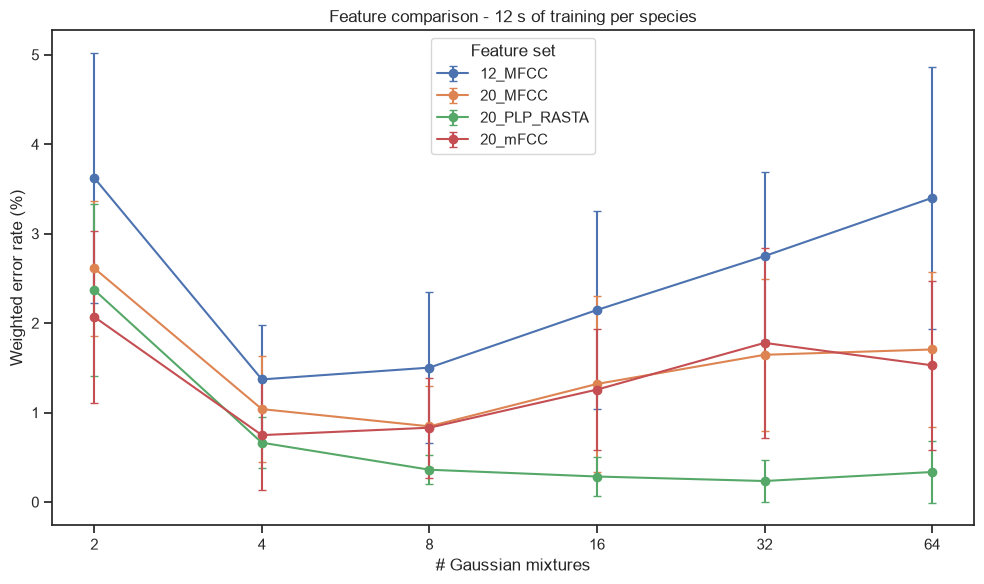

,fits,converged,max_iterations
feature,,,
12_MFCC,540,540,51
20_MFCC,540,540,56
20_PLP_RASTA,540,540,60
20_mFCC,540,540,55


In [8]:
# Summarise the ten repeats per condition, cross-check the m-FCC row against notebook 03, and draw the curves.
def summarise(wer: pd.DataFrame, keys) -> pd.DataFrame:
    return (wer.groupby(keys, as_index=False).WER_percent
            .agg(WER_mean="mean", WER_std="std", WER_min="min", WER_max="max"))


wer_summary = summarise(wer_fig9, ["feature", "n_components"])
comparison_wide = wer_summary.pivot(index="n_components", columns="feature", values="WER_mean")[list(FEATURE_NAMES)]
display(comparison_wide.round(3))

notebook_03 = pd.read_csv(PROCESSED_DIR / "gmm_parameter_investigation" / "wer_summary.csv")
reference = (notebook_03[notebook_03.training_seconds_target == 12]
             .set_index("n_components").WER_mean_percent.sort_index())
same = np.allclose(comparison_wide["20_mFCC"].to_numpy(), reference.to_numpy(), atol=1e-9, rtol=0)
print("20 m-FCC row identical to notebook 03 (12 s, mean WER %):", same)
assert same

fig, ax = plt.subplots(figsize=(10, 6))
for name in FEATURE_NAMES:
    sub = wer_summary[wer_summary.feature == name].sort_values("n_components")
    ax.errorbar(sub.n_components, sub.WER_mean, yerr=sub.WER_std, marker="o", capsize=3, label=name)
ax.set_xscale("log", base=2)
ax.set_xticks(N_COMPONENTS_GRID)
ax.set_xticklabels([str(m) for m in N_COMPONENTS_GRID])
ax.set(title="Feature comparison - 12 s of training per species", xlabel="# Gaussian mixtures",
       ylabel="Weighted error rate (%)")
ax.legend(title="Feature set")
plt.tight_layout()
plt.show()

convergence = per_species_fig9.groupby("feature").agg(fits=("converged", "size"), converged=("converged", "sum"),
                                                      max_iterations=("n_iter", "max"))
display(convergence)

`[OBSERVED]` The m-FCC row is **identical to notebook 03's 12-second results**, as it must be, since the features,
the splits and the random starts are the same. The comparison below therefore differs from notebook 03 only in
the feature sets it adds.

`[OBSERVED]` **12 MFCC has the highest error at every model order**, between 1.371 % (M=4) and 3.622 % (M=2).
20 MFCC is lower than 12 MFCC at every order.

`[OBSERVED]` **PLP-RASTA has the lowest error from M=4 upwards**, falling to **0.235 % at M=32**. m-FCC has the
lowest error only at M=2 (2.069 %, against 2.370 % for PLP-RASTA). From M=16 upwards PLP-RASTA stays between
0.235 % and 0.335 % while m-FCC rises to 1.779 % at M=32.

`[OBSERVED]` Every one of the 2160 fits converged, and the slowest needed 60 iterations.

## 9. The article's claims, quantified

**What this section asks, and why it matters.** Comparing two columns of means says which is lower,
not whether the gap is larger than the draw-to-draw spread. Because every feature set was run on the
same ten splits with the same seeds, the comparison can be **paired**: for each repeat, the difference
between two feature sets, then its mean, its standard error over the ten repeats, and how many repeats
favour the first set.

A difference is *first minus second*, in percentage points of WER, so a negative value means the first
set is better.

`[PAPER]` Three claims are tested: that 20 MFCC improves slightly on 12 MFCC, that PLP-RASTA improves
on MFCC by about 1 % above 16 mixtures, and that m-FCC surpasses the others. The article's abstract also
gives the WER at 64 Gaussians and 12 seconds: **0.9 %** for m-FCC, **3 %** for MFCC and **1.8 %** for PLP.

In [9]:
# Paired differences between feature sets on identical splits, and the abstract's headline numbers.
wide = wer_fig9.pivot_table(index=["n_components", "repeat"], columns="feature", values="WER_percent")

PAIRS = [("20_MFCC", "12_MFCC"), ("20_PLP_RASTA", "12_MFCC"), ("20_PLP_RASTA", "20_MFCC"),
         ("20_mFCC", "12_MFCC"), ("20_mFCC", "20_MFCC"), ("20_mFCC", "20_PLP_RASTA")]
rows = []
for first, second in PAIRS:
    diff = (wide[first] - wide[second]).unstack("repeat")
    for M in N_COMPONENTS_GRID:
        d = diff.loc[M]
        rows.append({"comparison": f"{first} - {second}", "M": M, "mean_diff_pp": d.mean(),
                     "std_error": d.std(ddof=1) / np.sqrt(len(d)), "first_better_in": int((d < 0).sum())})
paired = pd.DataFrame(rows)

display(paired.pivot(index="comparison", columns="M", values="mean_diff_pp").loc[[f"{a} - {b}" for a, b in PAIRS]].round(3))
print("repeats (of", N_REPEATS, ") in which the first set is better than the second:")
display(paired.pivot(index="comparison", columns="M", values="first_better_in").loc[[f"{a} - {b}" for a, b in PAIRS]])
print("largest standard error of any paired difference (pp):", round(paired.std_error.max(), 3))

headline = pd.DataFrame({
    "paper (abstract)": {"20_mFCC": 0.9, "12_MFCC": 3.0, "20_PLP_RASTA": 1.8, "20_MFCC": np.nan},
    "replication": comparison_wide.loc[64],
}).loc[list(FEATURE_NAMES)]
print("WER (%) at 64 Gaussians and 12 seconds:")
display(headline.round(3))

M,2,4,8,16,32,64
comparison,,,,,,
20_MFCC - 12_MFCC,-1.010,-0.332,-0.657,-0.827,-1.104,-1.695
20_PLP_RASTA - 12_MFCC,-1.252,-0.707,-1.141,-1.862,-2.515,-3.064
20_PLP_RASTA - 20_MFCC,-0.243,-0.375,-0.485,-1.035,-1.411,-1.370
20_mFCC - 12_MFCC,-1.553,-0.623,-0.672,-0.890,-0.970,-1.872
20_mFCC - 20_MFCC,-0.544,-0.291,-0.015,-0.063,0.133,-0.177
20_mFCC - 20_PLP_RASTA,-0.301,0.085,0.470,0.972,1.544,1.193


repeats (of 10 ) in which the first set is better than the second:


M,2,4,8,16,32,64
comparison,,,,,,
20_MFCC - 12_MFCC,7,8,8,9,9,9
20_PLP_RASTA - 12_MFCC,9,8,9,10,10,9
20_PLP_RASTA - 20_MFCC,6,7,7,9,10,8
20_mFCC - 12_MFCC,9,9,8,10,8,10
20_mFCC - 20_MFCC,8,5,5,4,5,6
20_mFCC - 20_PLP_RASTA,5,5,2,1,0,1


largest standard error of any paired difference (pp): 0.539
WER (%) at 64 Gaussians and 12 seconds:


,paper (abstract),replication
12_MFCC,3.0,3.400
20_MFCC,NaN,1.705
20_PLP_RASTA,1.8,0.335
20_mFCC,0.9,1.528


`[OBSERVED]` **20 MFCC against 12 MFCC.** 20 MFCC is better by 0.332 to 1.695 percentage points, and in 7 to 9 of
the 10 repeats at every model order. `[PAPER]` The article calls the improvement slight.

`[OBSERVED]` **PLP-RASTA against MFCC.** Against 20 MFCC the advantage is 1.411 points at M=32 and 1.370 at M=64,
and against 12 MFCC 2.515 and 3.064. PLP-RASTA is better in 10 of 10 repeats at M=16 and M=32 against 12 MFCC, and
at M=32 against 20 MFCC. `[PAPER]` The article reports an advantage of about 1 % above 16 mixtures, so the
direction is reproduced and the size here is the same or larger.

`[OBSERVED]` **m-FCC against the others.** m-FCC is better than 12 MFCC by 0.623 to 1.872 points in 8 to 10 of the 10
repeats. Against 20 MFCC the difference is between -0.544 and +0.133 points and m-FCC is better in only 4 to 8
repeats, and in 5 or fewer from M=4 to M=32. Against PLP-RASTA m-FCC is **worse from M=4 upwards**: +1.544 points at
M=32, where it is better in none of the 10 repeats.

`[INFERENCE]` With a largest standard error of 0.539 points, m-FCC and 20 MFCC cannot be told apart in this
replication, and the article's claim that the modified filter bank surpasses the others is **not reproduced**.
The article's filter bank is only estimated from a figure (notebook 02), so this says that *this reconstruction* of
it shows no advantage, not that the original had none.

`[OBSERVED]` **The abstract's figures at 64 Gaussians and 12 seconds.** 12 MFCC gives 3.400 % here against the
article's 3 %. m-FCC gives 1.528 % against 0.9 %, and PLP-RASTA 0.335 % against 1.8 %: the two are ranked the
other way round from the article.

## 10. Which species drive the differences at M = 64

**What this section asks, and why it matters.** A weighted error rate hides which classes carry it.
The article settles on `M = 64`, so the per-species error at that order shows whether the gaps between
feature sets come from a few hard species or from all of them.

In [10]:
# Per-species error at 64 components for each feature set, averaged over the ten repeats.
species_m64 = (per_species_fig9[per_species_fig9.n_components == 64]
               .groupby(["code", "feature"]).error_rate.mean().mul(100).unstack("feature")[list(FEATURE_NAMES)])
display(species_m64.round(3))

feature,12_MFCC,20_MFCC,20_PLP_RASTA,20_mFCC
code,,,,
f01,0.000,0.000,0.000,0.000
f02,5.452,5.186,0.427,2.793
f03,10.787,4.884,0.201,3.956
f04,0.955,0.955,0.064,0.702
f05,0.296,0.000,0.066,0.000
f06,2.196,0.370,0.000,0.000
f07,1.963,0.868,2.262,0.602
f08,7.974,2.734,0.000,4.897
f10,0.975,0.348,0.000,0.801


`[OBSERVED]` The differences between feature sets are carried by `f02`, `f03` and `f08`. For `f03`, 12 MFCC errs
10.787 % of the time, m-FCC 3.956 % and PLP-RASTA 0.201 %; for `f08` the values are 7.974 %, 4.897 % and 0.000 %.
`f01` is never misidentified by any feature set.

`[OBSERVED]` `f07` is the exception: PLP-RASTA errs 2.262 % there, the highest of the four feature sets (12 MFCC
1.963 %, 20 MFCC 0.868 %, m-FCC 0.602 %).

## 11. Figure 8: 12 MFCC with 6, 12 and 18 seconds

**What this section asks, and why it matters.** Notebook 03 could not reproduce the article's Figure 8
because it is drawn with 12 MFCC, which that notebook did not have. With the 12 MFCC built above, the
experiment of Figure 8 can be run as the article describes it: the three training durations against the
six model orders.

`[PAPER]` Section 4.1 reads Figure 8 as follows: for the three durations the error falls from 2 to 16
mixtures and levels off at 32 and 64; with 6 seconds it degrades as the model order grows. Its abstract
gives 3 % for MFCC at 64 Gaussians and 12 seconds.

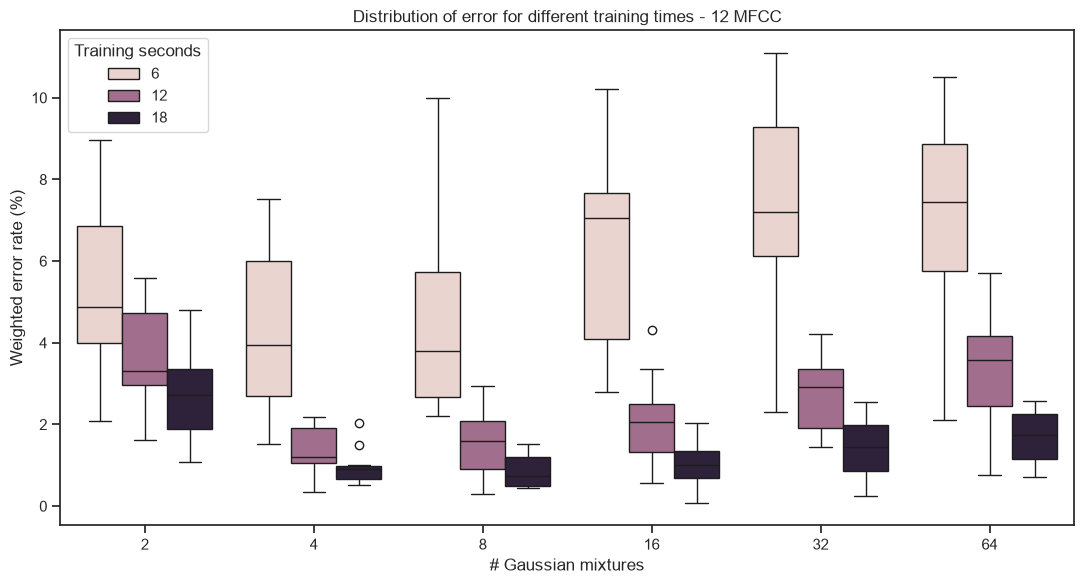

Mean WER (%) with 12 MFCC, by model order (rows) and training seconds (columns):


training_seconds_target,6,12,18
n_components,,,
2,5.313,3.622,2.779
4,4.369,1.371,0.981
8,4.508,1.502,0.848
16,6.324,2.147,1.062
32,7.416,2.749,1.430
64,7.129,3.400,1.693


In [11]:
# Run the 12 MFCC grid for 6 and 18 seconds, add the 12-second runs above, and draw the Figure 8 boxplot.
per_species_fig8 = pd.concat([
    per_species_fig9[per_species_fig9.feature == "12_MFCC"],
    run_grid(CORPORA, ("12_MFCC",), "paper", (6, 18)),
], ignore_index=True)
wer_fig8 = wer_by_repeat(per_species_fig8)
assert len(wer_fig8) == len(TRAINING_DURATIONS) * len(N_COMPONENTS_GRID) * N_REPEATS

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=wer_fig8, x="n_components", y="WER_percent", hue="training_seconds_target", ax=ax)
ax.set(title="Distribution of error for different training times - 12 MFCC",
       xlabel="# Gaussian mixtures", ylabel="Weighted error rate (%)")
ax.legend(title="Training seconds")
plt.tight_layout()
plt.show()

print("Mean WER (%) with 12 MFCC, by model order (rows) and training seconds (columns):")
display(wer_fig8.groupby(["n_components", "training_seconds_target"]).WER_percent.mean()
        .unstack("training_seconds_target").round(3))

`[OBSERVED]` More training audio lowers the 12 MFCC error at every model order, from 6 to 12 seconds and from 12 to 18.
At M=64 and 12 seconds the error is 3.400 %, which matches the article's 3 %.

`[OBSERVED]` With 6 seconds the error **rises with the model order**, from 4.369 % at M=4 to 7.416 % at M=32, and at
M=64 (7.129 %) it is above its M=2 value (5.313 %). `[PAPER]` This is the behaviour the article describes for 6 seconds.

`[OBSERVED]` With 12 and 18 seconds the error falls from M=2 to M=4 or M=8 (to 1.371 % and 0.848 %) and then **rises
again** to 3.400 % and 1.693 % at M=64. `[PAPER]` The article reads Figure 8 as levelling off at 32 and 64 components, which is
not what is observed here. This is the same shape as notebook 03 found with m-FCC.

## 12. Why does PLP-RASTA win? Starting the RASTA filter

**What this section asks, and why it matters.** PLP-RASTA beats the other three feature sets by a wide
margin in section 8, and whatever is chosen downstream inherits that result, so it has to be understood
before it is believed. One feature of the reconstruction is suspect. RASTA is a filter along time, and each
call is a short signal: the filter has to start from some state. Started from silence, its first output
frames are not yet filtered, so they still contain the call's raw spectral envelope. The other feature sets
have no such frames.

Two controls isolate the effect. PLP-RASTA with the filter started from the **steady state of the first frame**
(as if that frame had lasted forever, which removes the start-up transient), and **plain PLP** with no RASTA at all.
Everything else, including the splits and the seeds, is identical.

The article does not describe its PLP-RASTA implementation, so which start it used is unknown.

In [12]:
# Recompute PLP with a steady-state RASTA start and with no RASTA, and run the 12-second grid on both.
def extract_plp_variants(wav, start, end, rate):
    audio, sr = read_call_audio(wav, start, end, rate)
    return {"PLP_steady": F.plp_rasta(audio, sr, rasta="steady"), "PLP_no_rasta": F.plp_rasta(audio, sr, rasta=None)}


variants = Parallel(n_jobs=-1)(
    delayed(extract_plp_variants)(r.wav, r.start, r.end, r.rate) for r in calls.itertuples(index=False))
VARIANT_FEATURES = {cid: v for cid, v in zip(calls.call_id, variants)}

ABLATION_NAMES = {"20_PLP_RASTA": "PLP-RASTA, zero start (as built)", "PLP_steady": "PLP-RASTA, steady-state start",
                  "PLP_no_rasta": "PLP, no RASTA", "20_MFCC": "20 MFCC", "20_mFCC": "20 m-FCC"}
CORPORA_ABLATION = {**{n: CORPORA[n] for n in ("20_PLP_RASTA", "20_MFCC", "20_mFCC")},
                    **{n: corpus_from(VARIANT_FEATURES, n) for n in ("PLP_steady", "PLP_no_rasta")}}

per_species_ablation = pd.concat([
    per_species_fig9[per_species_fig9.feature.isin(["20_PLP_RASTA", "20_MFCC", "20_mFCC"])],
    run_grid(CORPORA_ABLATION, ("PLP_steady", "PLP_no_rasta"), "paper", (12,)),
], ignore_index=True)
wer_ablation = wer_by_repeat(per_species_ablation)

ablation_table = (summarise(wer_ablation, ["feature", "n_components"])
                  .pivot(index="feature", columns="n_components", values="WER_mean").loc[list(ABLATION_NAMES)])
ablation_table.index = [ABLATION_NAMES[i] for i in ablation_table.index]
print("Mean WER (%) at 12 s, paper protocol, by number of Gaussians:")
display(ablation_table.round(3))

early = {}
for name, matrices in (("zero start", CALL_FEATURES), ("steady start", VARIANT_FEATURES)):
    key = "20_PLP_RASTA" if name == "zero start" else "PLP_steady"
    early[name] = float(np.mean([np.linalg.norm(m[key][:5] - m[key][-5:]) for m in matrices.values()]))
print("mean distance between a call's first five and last five PLP frames:",
      {k: round(v, 2) for k, v in early.items()})

Mean WER (%) at 12 s, paper protocol, by number of Gaussians:


n_components,2,4,8,16,32,64
"PLP-RASTA, zero start (as built)",2.370,0.663,0.361,0.285,0.235,0.335
"PLP-RASTA, steady-state start",3.265,2.141,1.521,1.354,1.002,1.112
"PLP, no RASTA",2.078,0.813,0.721,1.065,1.103,1.291
20 MFCC,2.613,1.038,0.846,1.320,1.646,1.705
20 m-FCC,2.069,0.748,0.831,1.257,1.779,1.528


mean distance between a call's first five and last five PLP frames: {'zero start': 6.71, 'steady start': 0.64}


`[OBSERVED]` Started from a **steady state**, PLP-RASTA is 1.002 % to 3.265 % against 0.235 % to 2.370 % for the version as
built: from **3 to 5 times higher at M=4 and above**. In the as-built features the first and last five frames of a call are far
apart (mean distance 6.71) while with a steady start they are close (0.64), which is the unfiltered envelope showing in
the first frames.

`[OBSERVED]` With the steady start PLP-RASTA is **the worst of the five at M=2 to M=16** (for example 1.521 % at M=8 against 0.831 % for
m-FCC and 0.846 % for 20 MFCC), and it becomes the best of the sets other than the as-built one only from M=32, with 1.002 % at M=32 and 1.112 % at M=64.
Plain PLP without RASTA lies between: 0.721 % at M=8 and 1.291 % at M=64.

`[INFERENCE]` Most of the PLP-RASTA lead in section 8 comes from the start-up transient of the RASTA filter on each call,
not from a better spectral description of the species. It is a property of the reconstruction: the article does not
say how its PLP-RASTA treated the first frames, and this notebook cannot tell which is the faithful one.

## 13. An extension: holding whole recordings out

**What this section asks, and why it matters.** Notebook 03 showed that most validation calls come from
a recording that also supplied training calls. Within one recording the microphone, the room and the noise
floor are the same, so a feature that is sensitive to them can score well without recognising the species
at all. RASTA is designed to remove exactly that kind of constant coloration. If it works, it should matter
most when the validation recordings are *new*.

*This is not part of the article's protocol.* For each species, half of its source recordings (at least one)
are the training recordings and all calls from the others are validation, so no recording is on both sides.
`f05` has only three recordings, so training for some species is shorter than 12 seconds when the
training recordings hold less. The same grid is run for every feature set and for the two controls of
section 12.

Mean WER (%) with whole recordings held out (12 s), by number of Gaussians:


n_components,2,4,8,16,32,64
12 MFCC,27.790,30.196,32.932,33.528,34.408,34.136
"PLP-RASTA, zero start (as built)",9.776,4.931,5.207,5.693,6.789,8.165
"PLP-RASTA, steady-state start",8.026,6.137,6.026,7.159,8.630,10.892
"PLP, no RASTA",21.275,24.884,25.862,27.849,28.037,24.681
20 MFCC,23.250,26.348,29.111,28.974,30.199,26.697
20 m-FCC,17.903,21.777,23.381,26.942,26.093,26.306



mean training seconds actually available per species under this split:
code
f01    12.24
f02    12.19
f03    12.33
f04    12.12
f05    10.76
f06     8.91
f07    12.34
f08    12.54
f10    12.20


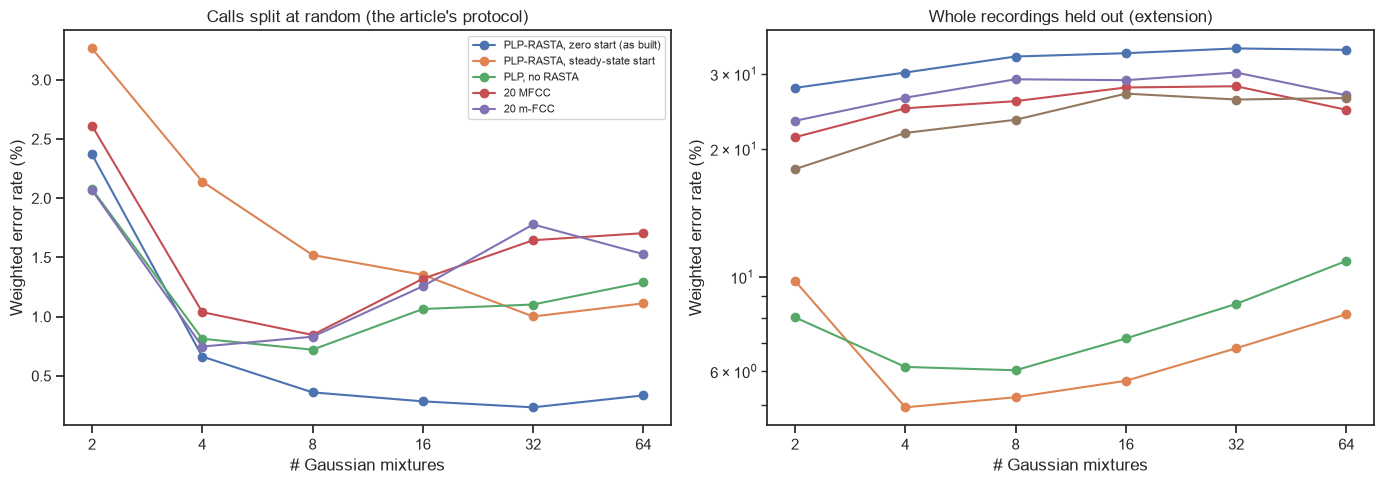

In [13]:
# Run the whole-recording split for every feature set and for the two PLP controls, at 12 seconds.
CORPORA_HELD_OUT = {**CORPORA, **{n: CORPORA_ABLATION[n] for n in ("PLP_steady", "PLP_no_rasta")}}
HELD_OUT_NAMES = {"12_MFCC": "12 MFCC", **ABLATION_NAMES}

per_species_held_out = run_grid(CORPORA_HELD_OUT, tuple(HELD_OUT_NAMES), "recordings", (12,))
wer_held_out = wer_by_repeat(per_species_held_out)
assert len(wer_held_out) == len(HELD_OUT_NAMES) * len(N_COMPONENTS_GRID) * N_REPEATS

held_out_table = (summarise(wer_held_out, ["feature", "n_components"])
                  .pivot(index="feature", columns="n_components", values="WER_mean").loc[list(HELD_OUT_NAMES)])
held_out_table.index = [HELD_OUT_NAMES[i] for i in held_out_table.index]
print("Mean WER (%) with whole recordings held out (12 s), by number of Gaussians:")
display(held_out_table.round(3))

training_actual = per_species_held_out[per_species_held_out.feature == "20_mFCC"].groupby("code").training_seconds_actual.mean()
print("\nmean training seconds actually available per species under this split:")
print(training_actual.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, (title, table) in zip(axes, (("Calls split at random (the article's protocol)", ablation_table),
                                     ("Whole recordings held out (extension)", held_out_table))):
    for name, row in table.iterrows():
        ax.plot(N_COMPONENTS_GRID, row.to_numpy(), marker="o", label=name)
    ax.set_xscale("log", base=2)
    ax.set_xticks(N_COMPONENTS_GRID)
    ax.set_xticklabels([str(m) for m in N_COMPONENTS_GRID])
    ax.set(title=title, xlabel="# Gaussian mixtures", ylabel="Weighted error rate (%)")
axes[1].set_yscale("log")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

`[OBSERVED]` When whole recordings are held out the error is **far higher for every feature set without RASTA**: 17.903 % to 34.408 % for
12 MFCC, 20 MFCC, m-FCC and plain PLP, against 0.721 % to 3.622 % for the same four sets in the article's protocol. Only the two
RASTA versions stay low, at 4.931 % to 9.776 % (as built) and 6.026 % to 10.892 % (steady start).

`[OBSERVED]` Plain PLP, which differs from PLP-RASTA only by the temporal filter, is at 21.275 % to 28.037 % (24.681 % at M=64): RASTA lowers the error by
more than 11 points at every order, for example from 28.037 % to 6.789 % at M=32. The as-built version stays ahead of the steady start from M=4 upwards (4.931 % against 6.137 % at M=4, 8.165 % against
10.892 % at M=64), so the transient helps a little here as well (steady is better only at M=2), but the effect of RASTA itself is several times larger.

`[OBSERVED]` Under this split some species have less than 12 seconds of training material: `f06` 8.91 seconds and `f05` 10.76 seconds, on average.

`[INFERENCE]` Inside one recording the channel (microphone, room, noise floor) is constant, so removing a constant colouration does not
help, and in the article's protocol RASTA gives little benefit beyond the start-up transient (steady start 1.002 % against 1.103 % without
RASTA at M=32, and worse below M=32). Across recordings it is exactly what is needed, and the difference is very large. The pond recordings of the testing stage were made with different equipment
(`[PAPER]` Section 4.3), which is the second situation, not the first. This is a crude protocol of this notebook, not the article's, and
it is meant to show the size of the effect, not to measure the performance a detector would have.

## 14. Save what later notebooks need

**What this section asks, and why it matters.** Later notebooks read the per-call features of the four
standard sets from one file, so that they do not repeat the extraction. That file must not change by being
rebuilt here, or every result computed from it would silently change. Before it is overwritten it is compared
with the file already on disk.

In [14]:
# Compare the call features with the stored cache, keep it if they agree, and write the experiment tables.
CACHE_PATH = RESULTS_DIR / "call_feature_sets.joblib"
TOLERANCE = 1e-9


def cache_difference(previous: dict, current: dict) -> float:
    """Largest absolute difference between two caches, or infinity if their structure differs."""
    if previous.keys() != current.keys():
        return float("inf")
    worst = 0.0
    for call_id in current:
        for name in FEATURE_NAMES:
            a, b = previous[call_id][name], current[call_id][name]
            if a.shape != b.shape:
                return float("inf")
            worst = max(worst, float(np.abs(a - b).max()))
    return worst


write_cache = True
if CACHE_PATH.exists():
    difference = cache_difference(joblib.load(CACHE_PATH), CALL_FEATURES)
    print("largest absolute difference from the cache on disk:", f"{difference:.1e}")
    write_cache = difference > TOLERANCE
else:
    print("no previous cache on disk")

if write_cache:
    joblib.dump(CALL_FEATURES, CACHE_PATH, compress=3)
    print("cache written")
else:
    print("cache on disk kept: it agrees with these features within", TOLERANCE)

on_disk = joblib.load(CACHE_PATH)
print("cache on disk matches the features in memory:", cache_difference(on_disk, CALL_FEATURES) <= TOLERANCE)

OUTPUTS = {
    "feature_validation.csv": feature_validation,
    "per_species_results.csv": per_species_fig9,
    "wer_by_repeat.csv": wer_fig9,
    "wer_summary.csv": wer_summary,
    "paired_differences.csv": paired,
    "figure8_wer_by_repeat.csv": wer_fig8,
    "rasta_start_ablation_wer_by_repeat.csv": wer_ablation,
    "held_out_recordings_wer_by_repeat.csv": wer_held_out,
}
for name, table in OUTPUTS.items():
    table.to_csv(RESULTS_DIR / name, index=False)
comparison_wide.to_csv(RESULTS_DIR / "figure9_comparison_table.csv")

print("\nwritten to", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
for name in ["call_feature_sets.joblib", *OUTPUTS, "figure9_comparison_table.csv"]:
    print(f"  {name:<42} {(RESULTS_DIR / name).stat().st_size / 1e6:>7.2f} MB")

largest absolute difference from the cache on disk: 6.4e-14
cache on disk kept: it agrees with these features within 1e-09


cache on disk matches the features in memory: True

written to data/processed/feature_comparison
  call_feature_sets.joblib                     64.46 MB
  feature_validation.csv                        0.18 MB
  per_species_results.csv                       0.25 MB
  wer_by_repeat.csv                             0.01 MB
  wer_summary.csv                               0.00 MB
  paired_differences.csv                        0.00 MB
  figure8_wer_by_repeat.csv                     0.01 MB
  rasta_start_ablation_wer_by_repeat.csv        0.01 MB
  held_out_recordings_wer_by_repeat.csv         0.02 MB
  figure9_comparison_table.csv                  0.00 MB


`[OBSERVED]` The features rebuilt here differ from the cache stored by the previous version of this notebook by at most **6.4e-14**, so
the file on disk was **kept** and not rewritten: it agrees with the features in memory within the tolerance of 1e-09.

`[INFERENCE]` A difference of that size is floating-point rounding, not a change in any feature. Keeping the file means that
everything computed from it by later notebooks is still exactly reproducible.

## 15. Conclusions and limitations

**What this notebook delivers.** The feature-comparison experiment of Section 4.2 on the labelled calls: 240 conditions
(4 feature sets × 6 model orders × 10 random selections), all run on identical splits and random starts, plus the Figure 8
experiment with 12 MFCC that notebook 03 could not run. The per-call features of the four sets are kept in
`data/processed/feature_comparison/call_feature_sets.joblib`, and the baseline extractors live in `frog_presence.features` with tests.

**What was found.**

1. **The article's ordering is reproduced for MFCC only.** 12 MFCC is worst and 20 MFCC improves on it. PLP-RASTA beats both, by the margin
   the article reports or more at 32 and 64 Gaussians.
2. **m-FCC does not surpass the others.** It cannot be told apart from 20 MFCC and is beaten by PLP-RASTA from M=4 upwards. At 64 Gaussians
   and 12 seconds it gives 1.528 %, against 0.9 % in the article.
3. **Most of PLP-RASTA's lead depends on how the filter is started.** With a steady-state start its error is 3 to 5 times higher at M=4 and
   above, and it is the worst of the five sets below M=32.
4. **RASTA matters a great deal across recordings.** With whole recordings held out, features without RASTA have errors of 17.903 % to 34.408 %
   and the two RASTA versions 4.931 % to 10.892 %.
5. **Figure 8 is reproduced in behaviour for 6 seconds and in value at 64 Gaussians, 12 seconds (3.400 % against 3 %)**, but not in shape for 12
   and 18 seconds, where the error rises again instead of levelling off.

**Decisions taken here, which the article does not state.**

1. **MFCC:** 40 mel filters from 0 Hz to the Nyquist frequency, c0 counted among the 12 or 20 coefficients, as the m-FCC of notebook 02 do.
2. **PLP-RASTA:** 24 Bark bands, all-pole order 20, classic RASTA constants, and the filter started from silence on every call.
3. **The comparison is controlled:** one split and one random start per species, repeat and model order, whatever the feature set.
4. **Paired differences** over the ten repeats are used to compare feature sets, instead of the difference of two means.
5. **The held-out split** keeps half of each species' recordings for training and validates on the rest. It is an extension, not the article's protocol.

**Limitations.**

- **Both baselines are reconstructions.** The article gives no implementation parameters, so these are findings about *these* implementations.
- **The RASTA start is a choice that decides the PLP-RASTA result**, and the article does not say what it did. Both versions are reported and neither is
  declared the faithful one.
- **The RASTA constants were designed for a lower frame rate** than this front end produces, which changes the time constants of the filter. This is not tested here.
- **The article does not publish the numbers behind Figure 9**, so the comparison is made on its abstract's figures and on its qualitative claims.
- **The species set differs from the article's**: `f06` is present and `f09` cannot be modelled.
- **Training and validation share recordings in the article's protocol** (notebook 03), so its errors are optimistic for new recordings. The held-out split is a crude
  protocol with shorter training for `f05` and `f06`.
- **Ten selections** leave a standard error of up to 0.539 points on a paired difference.

**What the next stages inherit.** The per-call PLP-RASTA features handed over in the cache are the **zero-start** ones. Any model or threshold built on them depends on the
start-up transient examined in section 12.